# Per-event features, as DataFrames

One frame per group: `muatm`, `nuatm`, `nue2`, `exp`.

Each row is one event. Features come from three places: the hits (charge, timing and
geometry of the bright hits), the prediction database (prefilter score, hit counts) and,
for simulation only, `prime_prty` (zenith, energy, muon multiplicity, event weight).

Parts are restricted to those that were scored, are out of training, and have sig-noise
probabilities. `MAX_PARTS` and `EVENTS_PER_PART` bound the read — set them to `None` for
everything.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[3]))

import h5py
import numpy as np
import pandas as pd

from inference import reader

CHECKPOINT = "da_prefilter_numu_260428_2039"     # the control, trained without DA

GROUPS = {"muatm_2020": ("mc_merged", "muatm"),
          "nuatm_2020": ("mc_merged", "nuatm"),
          "nue2_2020":  ("mc_merged", "nue2"),
          "exp_full":   ("exp_full", None)}

BRIGHT_CHARGE_PE = 5.0
STRING_DIVISOR   = 36

TRAINING_PARTS_JSON = (Path(reader.spec.ROOT) /
                       "data_manager/datasets/baikal_mc2020_prefilter/prefilter_h5_parts.json")

## Loader

In [2]:
def available_parts(group):
    """Parts that were scored, are out of training, and have sig-noise probabilities.

    All three conditions matter: an unscored part has no score to join, a training part
    would bias anything measured on it, and a part missing from the probabilities file
    carries no signal-hit counts.
    """
    source, short_name = GROUPS[group]
    connection = reader.query.connect(reader.open_checkpoint(CHECKPOINT), source)
    restrict = f"WHERE e.data_class = '{group}'" if source == "mc_merged" else ""
    scored = {row[0] for row in connection.execute(f"""
        SELECT DISTINCT l.part_key
        FROM predictions p
        JOIN cat.events e ON e.id = p.event_fk
        JOIN cat.h5_locations l ON l.event_fk = p.event_fk
        {restrict}""").fetchall()}
    connection.close()

    if source == "exp_full":
        return sorted(scored - set(reader.spec.SOURCES["exp_full"].bad_runs))

    trained = {f"part_{number}"
               for number in json.loads(TRAINING_PARTS_JSON.read_text())[short_name]}
    with h5py.File(reader.spec.SOURCES["mc_merged"].probs, "r") as handle:
        with_probabilities = set(handle[group]["n_sig_hits_0.8"].keys())
    return sorted(scored & with_probabilities - trained,
                  key=lambda part: int(part.split("_")[1]))


def hit_derived_features(group, parts, events_per_part=None,
                         charge_threshold=BRIGHT_CHARGE_PE):
    """Per-event features built from the hits, read contiguously straight from HDF5.

    `reader.stream` is the wrong tool for this: it addresses selected events, and for a
    sparse selection it reads about 68 hits for every one it returns. Here whole parts are
    wanted, so reading them in file order is both simpler and far faster.
    """
    source, _ = GROUPS[group]
    is_simulation = source == "mc_merged"
    collected = []

    with h5py.File(reader.spec.SOURCES[source].h5, "r") as handle:
        hdf5_group = handle[group]
        for part_key in parts:
            boundaries = hdf5_group[f"raw/ev_starts/{part_key}/data"][:].astype(np.int64)
            n_events = min(events_per_part or len(boundaries) - 1, len(boundaries) - 1)
            if n_events == 0:
                continue
            hits = hdf5_group[f"raw/data/{part_key}/data"][:int(boundaries[n_events])]
            channels = hdf5_group[f"raw/channels/{part_key}/data"][
                :int(boundaries[n_events])].astype(np.int64)
            charge, time_ns, x, y, z = (hits[:, 0], hits[:, 1],
                                        hits[:, 2], hits[:, 3], hits[:, 4])

            hits_per_event = (boundaries[1:n_events + 1]
                              - boundaries[:n_events]).astype(np.int64)
            event_of_hit = np.repeat(np.arange(n_events), hits_per_event)
            bright = charge > charge_threshold
            bright_per_event = np.bincount(event_of_hit[bright], minlength=n_events)
            has_bright = bright_per_event > 0
            bright_starts = np.concatenate(
                [[0], np.cumsum(bright_per_event)])[:-1][has_bright]

            frame = pd.DataFrame({
                "part_key": part_key,
                "local_idx": np.arange(n_events, dtype=np.int64),
                "n_hits": hits_per_event.astype(np.int32),
                "bright_hits": bright_per_event.astype(np.int32),
            })
            for name in ("time_span_of_bright_hits_ns", "vertical_span_of_bright_hits_m",
                         "horizontal_span_of_bright_hits_m", "brightest_hit_pe",
                         "charge_in_bright_hits_pe"):
                frame[name] = np.nan

            span = lambda values: (np.maximum.reduceat(values[bright], bright_starts)
                                   - np.minimum.reduceat(values[bright], bright_starts))
            frame.loc[has_bright, "time_span_of_bright_hits_ns"] = span(time_ns)
            frame.loc[has_bright, "vertical_span_of_bright_hits_m"] = span(z)
            frame.loc[has_bright, "horizontal_span_of_bright_hits_m"] = np.hypot(span(x),
                                                                                 span(y))
            frame.loc[has_bright, "brightest_hit_pe"] = np.maximum.reduceat(
                charge[bright], bright_starts)
            frame.loc[has_bright, "charge_in_bright_hits_pe"] = np.add.reduceat(
                charge[bright], bright_starts)

            keyed = event_of_hit[bright] * 1000 + channels[bright] // STRING_DIVISOR
            frame["strings_with_a_bright_hit"] = np.bincount(
                (np.unique(keyed) // 1000).astype(np.int64),
                minlength=n_events).astype(np.int32)

            starts = boundaries[:n_events].astype(np.intp)
            frame["time_span_of_all_hits_ns"] = (
                np.maximum.reduceat(time_ns, starts)
                - np.minimum.reduceat(time_ns, starts))

            if is_simulation:
                truth = hdf5_group[f"prime_prty/{part_key}/data"][:n_events]
                frame["zenith_deg"] = truth[:, 0]
                frame["primary_energy_gev"] = truth[:, 2]
                frame["muon_multiplicity"] = truth[:, 4]
                frame["event_weight"] = truth[:, 5]

            collected.append(frame)
    return pd.concat(collected, ignore_index=True)


def stored_predictions(group, parts):
    """Score and hit counts from the prediction database, keyed by (part, local index).

    `data_class` is not optional for MC: part names repeat across muatm, nuatm and nue2,
    so a join on the part key alone silently pulls in other classes and duplicates events.
    """
    source, _ = GROUPS[group]
    connection = reader.query.connect(reader.open_checkpoint(CHECKPOINT), source)
    listed = ", ".join(f"'{part}'" for part in parts)
    restrict = f"AND e.data_class = '{group}'" if source == "mc_merged" else ""
    frame = connection.execute(f"""
        SELECT l.part_key, l.local_idx, p.event_fk, p.score,
               p.n_hits AS n_hits_in_database,
               p.n_sn_hits, p.n_sn_strings, p.n_gt_sig_hits, p.n_gt_sig_strings
        FROM predictions p
        JOIN cat.events e ON e.id = p.event_fk
        JOIN cat.h5_locations l ON l.event_fk = p.event_fk
        WHERE l.part_key IN ({listed}) {restrict}
    """).df()
    connection.close()
    assert not frame.duplicated(["part_key", "local_idx"]).any(), \
        f"{group}: (part_key, local_idx) is not unique — the join is wrong"
    return frame


def load_events(group, max_parts=None, events_per_part=None,
                charge_threshold=BRIGHT_CHARGE_PE):
    """One DataFrame of per-event features for `group`.

    `max_parts` and `events_per_part` bound the read; leave them None for everything.
    Events the prediction database does not carry are dropped, and how many is reported.
    """
    parts = available_parts(group)[:max_parts]
    features = hit_derived_features(group, parts, events_per_part, charge_threshold)
    predictions = stored_predictions(group, parts)
    merged = features.merge(predictions, on=["part_key", "local_idx"], how="inner")

    mismatched = int((merged.n_hits != merged.n_hits_in_database).sum())
    assert mismatched == 0, (
        f"{group}: {mismatched} events disagree on n_hits between HDF5 and the database "
        f"— the addressing is wrong")
    merged = merged.drop(columns="n_hits_in_database")

    print(f"{group}: {len(parts)} parts, {len(features):,} events read, "
          f"{len(merged):,} with a score "
          f"({len(features) - len(merged):,} dropped)")
    return merged

## The four frames

In [ ]:
MAX_PARTS = {"muatm_2020": 60, "nuatm_2020": 60, "nue2_2020": 60, "exp_full": None}
EVENTS_PER_PART = {"muatm_2020": None, "nuatm_2020": None, "nue2_2020": None,
                   "exp_full": 200_000}

muatm = load_events("muatm_2020", MAX_PARTS["muatm_2020"], EVENTS_PER_PART["muatm_2020"])
nuatm = load_events("nuatm_2020", MAX_PARTS["nuatm_2020"], EVENTS_PER_PART["nuatm_2020"])
nue2 = load_events("nue2_2020", MAX_PARTS["nue2_2020"], EVENTS_PER_PART["nue2_2020"])
exp = load_events("exp_full", MAX_PARTS["exp_full"], EVENTS_PER_PART["exp_full"])

In [ ]:
pd.DataFrame({name: {"events": len(frame), "parts": frame.part_key.nunique(),
                     "columns": frame.shape[1],
                     "with at least one bright hit":
                         float(frame.bright_hits.gt(0).mean()),
                     "median n_hits": frame.n_hits.median(),
                     "median score": frame.score.median()}
              for name, frame in (("muatm", muatm), ("nuatm", nuatm),
                                  ("nue2", nue2), ("exp", exp))})

,muatm,nuatm,nue2,exp
events,1.960289e+06,2.365886e+06,1.175817e+06,5.400000e+06
parts,6.000000e+01,6.000000e+01,6.000000e+01,2.700000e+01
columns,2.100000e+01,2.100000e+01,2.100000e+01,1.700000e+01
with at least one bright hit,9.175086e-01,9.104961e-01,9.642444e-01,9.270839e-01
median n_hits,6.100000e+01,6.000000e+01,7.800000e+01,6.100000e+01
median score,8.306731e-03,1.725678e-01,9.631071e-01,1.919815e-02


## Columns

In [ ]:
pd.DataFrame({"muatm": muatm.dtypes, "exp": exp.dtypes}).rename_axis("column")

,muatm,exp
column,,
bright_hits,int32,int32
brightest_hit_pe,float64,float64
charge_in_bright_hits_pe,float64,float64
event_fk,int64,int64
event_weight,float32,NaN
horizontal_span_of_bright_hits_m,float64,float64
local_idx,int64,int64
muon_multiplicity,float32,NaN
n_gt_sig_hits,int32,Int32


In [ ]:
muatm.head()

,part_key,local_idx,n_hits,bright_hits,time_span_of_bright_hits_ns,vertical_span_of_bright_hits_m,horizontal_span_of_bright_hits_m,brightest_hit_pe,charge_in_bright_hits_pe,strings_with_a_bright_hit,...,zenith_deg,primary_energy_gev,muon_multiplicity,event_weight,event_fk,score,n_sn_hits,n_sn_strings,n_gt_sig_hits,n_gt_sig_strings
0,part_1001,0,55,1,0.000000,0.000000,0.000000,11.359815,11.359815,1,...,142.908905,198.664078,5.0,1.0,359480,0.002550,3,1,4,2
1,part_1001,1,59,1,0.000000,0.000000,0.000000,6.016813,6.016813,1,...,158.411148,12.159861,1.0,1.0,359481,0.030237,0,0,0,0
2,part_1001,2,65,2,2106.261230,75.073990,0.000000,15.907464,21.372232,1,...,166.602722,3.860560,1.0,1.0,359482,0.007772,2,1,2,1
3,part_1001,3,51,4,2392.315186,360.125000,114.682129,18.747009,45.108261,2,...,148.043625,10.512264,1.0,1.0,359483,0.008240,0,0,2,1
4,part_1001,4,68,4,1612.570068,120.041008,62.742195,15.181597,41.090759,2,...,139.395020,28.497351,2.0,1.0,359484,0.165972,2,1,6,4


## Save

In [ ]:
DESTINATION = Path("event_features")
DESTINATION.mkdir(exist_ok=True)
for name, frame in (("muatm", muatm), ("nuatm", nuatm), ("nue2", nue2), ("exp", exp)):
    path = DESTINATION / f"{name}.parquet"
    frame.to_parquet(path)
    print(f"{path}  {path.stat().st_size / 1e6:.0f} MB")

event_features/muatm.parquet  96 MB
event_features/nuatm.parquet  122 MB
event_features/nue2.parquet  67 MB
event_features/exp.parquet  219 MB


In [7]:
# LOAD
DESTINATION = Path("event_features")
FRAMES = {}
for name in ("muatm", "nuatm", "nue2", "exp"):
    path = DESTINATION / f"{name}.parquet"
    frame = pd.read_parquet(path)
    FRAMES[name] = frame
    print(f"{path}  {len(frame):,} events, {frame.part_key.nunique():,} parts, "
          f"{frame.shape[1]} columns")
muatm = FRAMES["muatm"]
exp = FRAMES["exp"]

event_features/muatm.parquet  1,960,289 events, 60 parts, 21 columns
event_features/nuatm.parquet  2,365,886 events, 60 parts, 21 columns
event_features/nue2.parquet  1,175,817 events, 60 parts, 21 columns
event_features/exp.parquet  5,400,000 events, 27 parts, 17 columns


# Score dists after matches

In [8]:
import matplotlib.pyplot as plt 
hist_kwargs = dict(density=True, bins=50, alpha=0.5, histtype='step')

Text(0.5, 0, 'N raw hits')

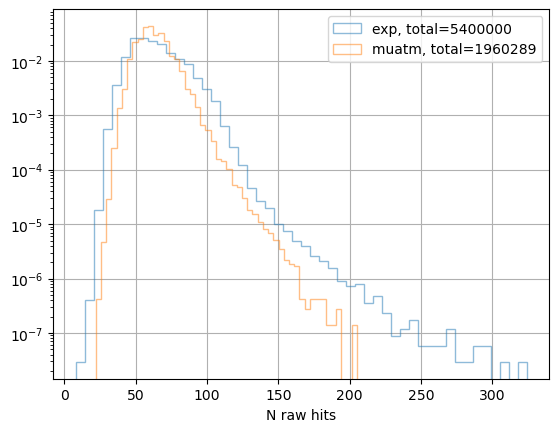

In [9]:
exp.n_hits.hist(label=f"exp, total={len(exp)}", log=True, **hist_kwargs)
muatm.n_hits.hist(label=f"muatm, total={len(muatm)}", log=True, **hist_kwargs)
plt.legend()
plt.xlabel("N raw hits")

NameError: name 'nuatm' is not defined

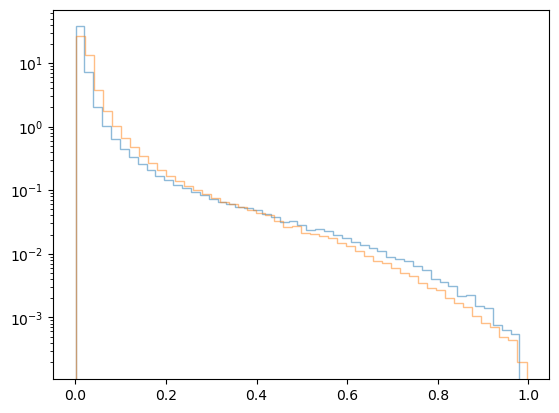

In [10]:
plt.hist(muatm.score, label=f"muatm, total={len(muatm)}", log=True,**hist_kwargs)
plt.hist(exp.score, label=f"exp, total={len(exp)}", log=True,**hist_kwargs)
plt.hist(nuatm.score, label=f"nuatm, total={len(nuatm)}", log=True,**hist_kwargs)  
plt.xlabel("Score")
plt.ylabel("Density")
plt.legend()
plt.show()

def _apply_mask(df: pd.DataFrame):
    mask = (df.n_sn_hits >= 8)
    #mask &= (df.n_hits < 100)
    return df[mask].copy()

plt.hist(_apply_mask(muatm).score, label=f"muatm, total={len(_apply_mask(muatm))}", log=True,**hist_kwargs)
plt.hist(_apply_mask(exp).score, label=f"exp, total={len(_apply_mask(exp))}", log=True,**hist_kwargs)
plt.xlabel("Score")
plt.ylabel("Density")
plt.legend()
plt.show()

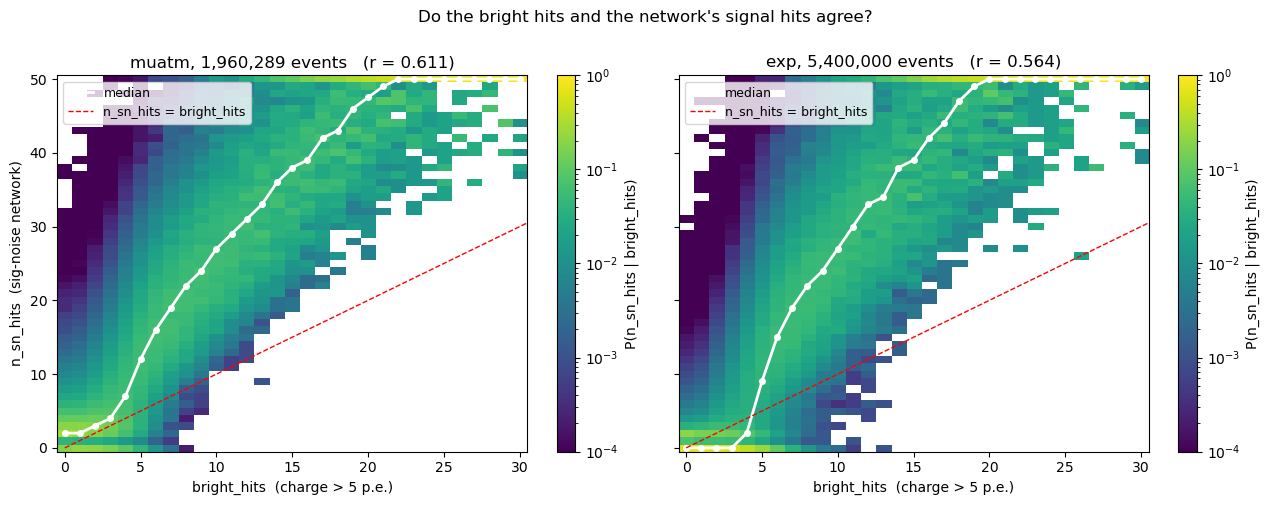

In [11]:
from matplotlib.colors import LogNorm

# Both counts are integers, so one bin per value is exact — no binning choice to make.
# Everything above the cap is clipped into the last bin rather than dropped.
bright_cap, signal_cap = 30, 50
bright_edges = np.arange(-0.5, bright_cap + 1.5)
signal_edges = np.arange(-0.5, signal_cap + 1.5)

def counts_2d(df):
    return np.histogram2d(np.clip(df.bright_hits, 0, bright_cap),
                          np.clip(df.n_sn_hits, 0, signal_cap),
                          bins=[bright_edges, signal_edges])[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (name, df) in zip(axes, (("muatm", muatm), ("exp", exp))):
    counts = counts_2d(df)
    # Column-normalised: P(n_sn_hits | bright_hits). The two groups have very different
    # bright_hits spectra, and a joint density would mostly show that instead.
    with np.errstate(divide="ignore", invalid="ignore"):
        conditional = counts / counts.sum(axis=1, keepdims=True)
    image = ax.imshow(np.ma.masked_invalid(conditional).T, origin="lower", aspect="auto",
                      extent=[-0.5, bright_cap + 0.5, -0.5, signal_cap + 0.5],
                      cmap="viridis", norm=LogNorm(vmin=1e-4, vmax=1))
    centres = np.arange(bright_cap + 1)
    capped = np.clip(df.bright_hits, 0, bright_cap)
    median = [np.median(np.clip(df.n_sn_hits[capped == b], 0, signal_cap))
              if (capped == b).any() else np.nan for b in centres]
    ax.plot(centres, median, color="white", lw=2, marker="o", ms=4, label="median")
    ax.plot([0, signal_cap], [0, signal_cap], color="red", lw=1, ls="--",
            label="n_sn_hits = bright_hits")
    ax.set(title=f"{name}, {len(df):,} events   (r = {df.bright_hits.corr(df.n_sn_hits):.3f})",
           xlabel="bright_hits  (charge > 5 p.e.)", xlim=(-0.5, bright_cap + 0.5))
    ax.legend(loc="upper left", fontsize=9)
    fig.colorbar(image, ax=ax, label="P(n_sn_hits | bright_hits)")

axes[0].set_ylabel("n_sn_hits  (sig-noise network)")
fig.suptitle("Do the bright hits and the network's signal hits agree?", y=1.00)
fig.tight_layout()
plt.show()

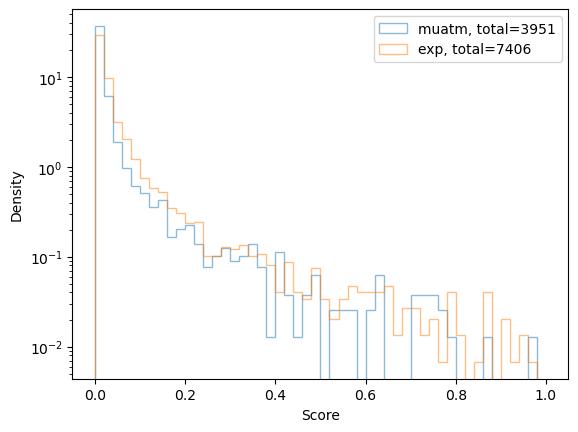

In [ ]:
def _apply_mask(df: pd.DataFrame):
    mask = (df.bright_hits == 5)
    mask &= (df.n_hits < 60)
    mask &= (df.n_hits >= 30)
    return df[mask].copy()

plt.hist(_apply_mask(muatm).score, label=f"muatm, total={len(_apply_mask(muatm))}", log=True, range=(0, 1), **hist_kwargs)
plt.hist(_apply_mask(exp).score, label=f"exp, total={len(_apply_mask(exp))}", log=True, range=(0, 1), **hist_kwargs)
#plt.hist(_apply_mask(nue2).score, label=f"nue2, total={len(_apply_mask(nue2))}", ls='--', log=True, range=(0, 1), **hist_kwargs)
#plt.hist(_apply_mask(nuatm).score, label=f"nuatm, total={len(_apply_mask(nuatm))}", ls='--', log=True, range=(0, 1), **hist_kwargs)
plt.xlabel("Score")
plt.ylabel("Density")
plt.legend()
plt.show()

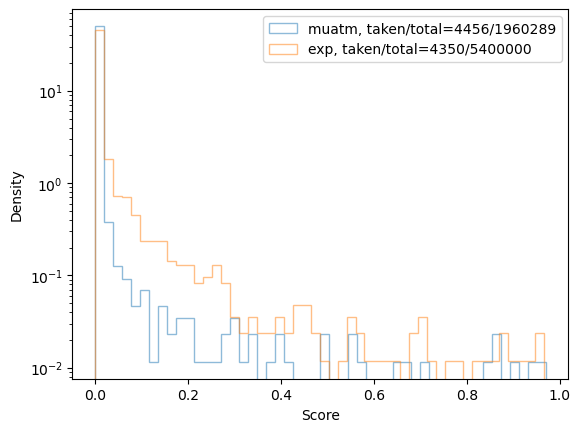

In [12]:
def _apply_mask(df: pd.DataFrame):
    #mask = (df.n_sn_hits==4)
    mask = (df.bright_hits==6)
    #mask &= (df.bright_hits/df.n_hits >=0.05) #& (df.bright_hits/df.n_hits < 0.06) #(df.bright_hits >= 5) & (df.n_hits >= 50)
    mask &= (df.n_hits >= 70) & (df.n_hits < 80)
    return df[mask].copy()

  
plt.hist(_apply_mask(muatm).score, label=f"muatm, taken/total={len(_apply_mask(muatm))}/{len(muatm)}", log=True,**hist_kwargs)
plt.hist(_apply_mask(exp).score, label=f"exp, taken/total={len(_apply_mask(exp))}/{len(exp)}", log=True,**hist_kwargs)
plt.xlabel("Score")
plt.ylabel("Density")
plt.legend()
plt.show()

## Score against the bright-hit fraction

/tmp/ipykernel_179133/2681290166.py:27: RuntimeWarning: divide by zero encountered in divide
  ratio = ((counts["exp"] / counts["exp"].sum())
/tmp/ipykernel_179133/2681290166.py:27: RuntimeWarning: invalid value encountered in divide
  ratio = ((counts["exp"] / counts["exp"].sum())


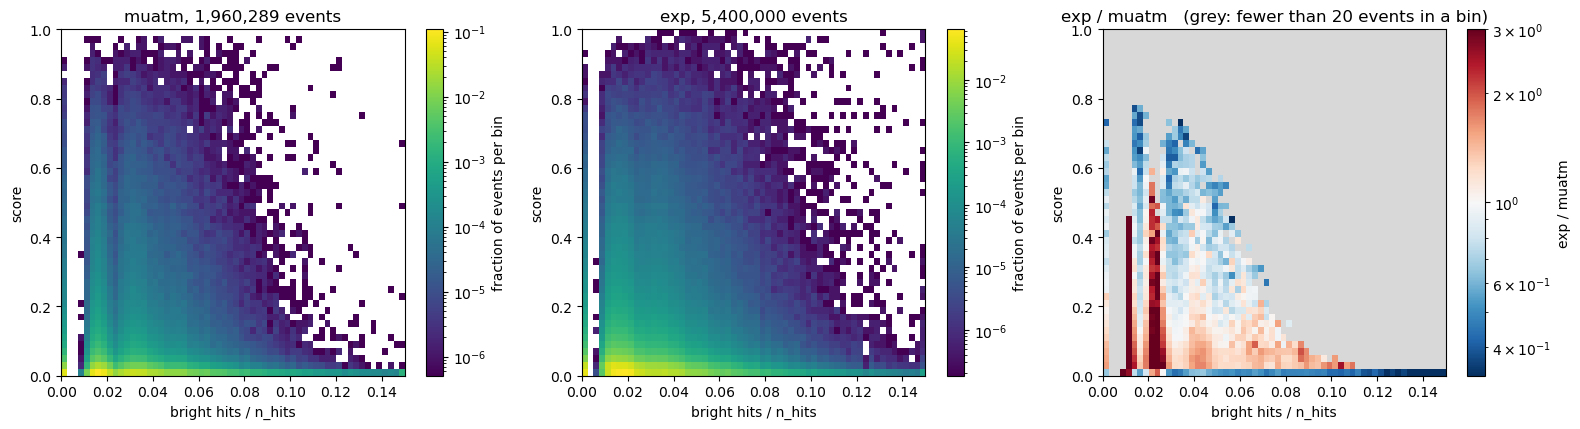

In [ ]:
from matplotlib.colors import LogNorm

score_bins = np.linspace(0, 1, 51)
fraction_bins = np.linspace(0, 0.15, 61)     # p99.9 is 0.12 (exp) and 0.16 (muatm)

def bright_fraction(df):
    # Anything above the last edge goes into it rather than out of the histogram.
    return np.clip(df.bright_hits / df.n_hits, fraction_bins[0], fraction_bins[-1] - 1e-9)

counts = {name: np.histogram2d(df.score, bright_fraction(df),
                               bins=[score_bins, fraction_bins])[0]
          for name, df in (("muatm", muatm), ("exp", exp))}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
extent = [fraction_bins[0], fraction_bins[-1], score_bins[0], score_bins[-1]]

for ax, name in zip(axes, ("muatm", "exp")):
    density = counts[name] / counts[name].sum()
    image = ax.imshow(np.ma.masked_where(density == 0, density), origin="lower",
                      aspect="auto", extent=extent, norm=LogNorm(), cmap="viridis")
    ax.set(title=f"{name}, {counts[name].sum():,.0f} events",
           xlabel="bright hits / n_hits", ylabel="score")
    fig.colorbar(image, ax=ax, label="fraction of events per bin")

# A ratio built on a few events is noise, so those bins stay blank.
too_few = (counts["muatm"] < 20) | (counts["exp"] < 20)
ratio = ((counts["exp"] / counts["exp"].sum())
         / (counts["muatm"] / counts["muatm"].sum()))
image = axes[2].imshow(np.ma.masked_where(too_few, ratio), origin="lower", aspect="auto",
                       extent=extent, cmap="RdBu_r", norm=LogNorm(vmin=1/3, vmax=3))
image.cmap.set_bad("0.85")
axes[2].set(title="exp / muatm   (grey: fewer than 20 events in a bin)",
            xlabel="bright hits / n_hits", ylabel="score")
fig.colorbar(image, ax=axes[2], label="exp / muatm")

fig.tight_layout()
plt.show()

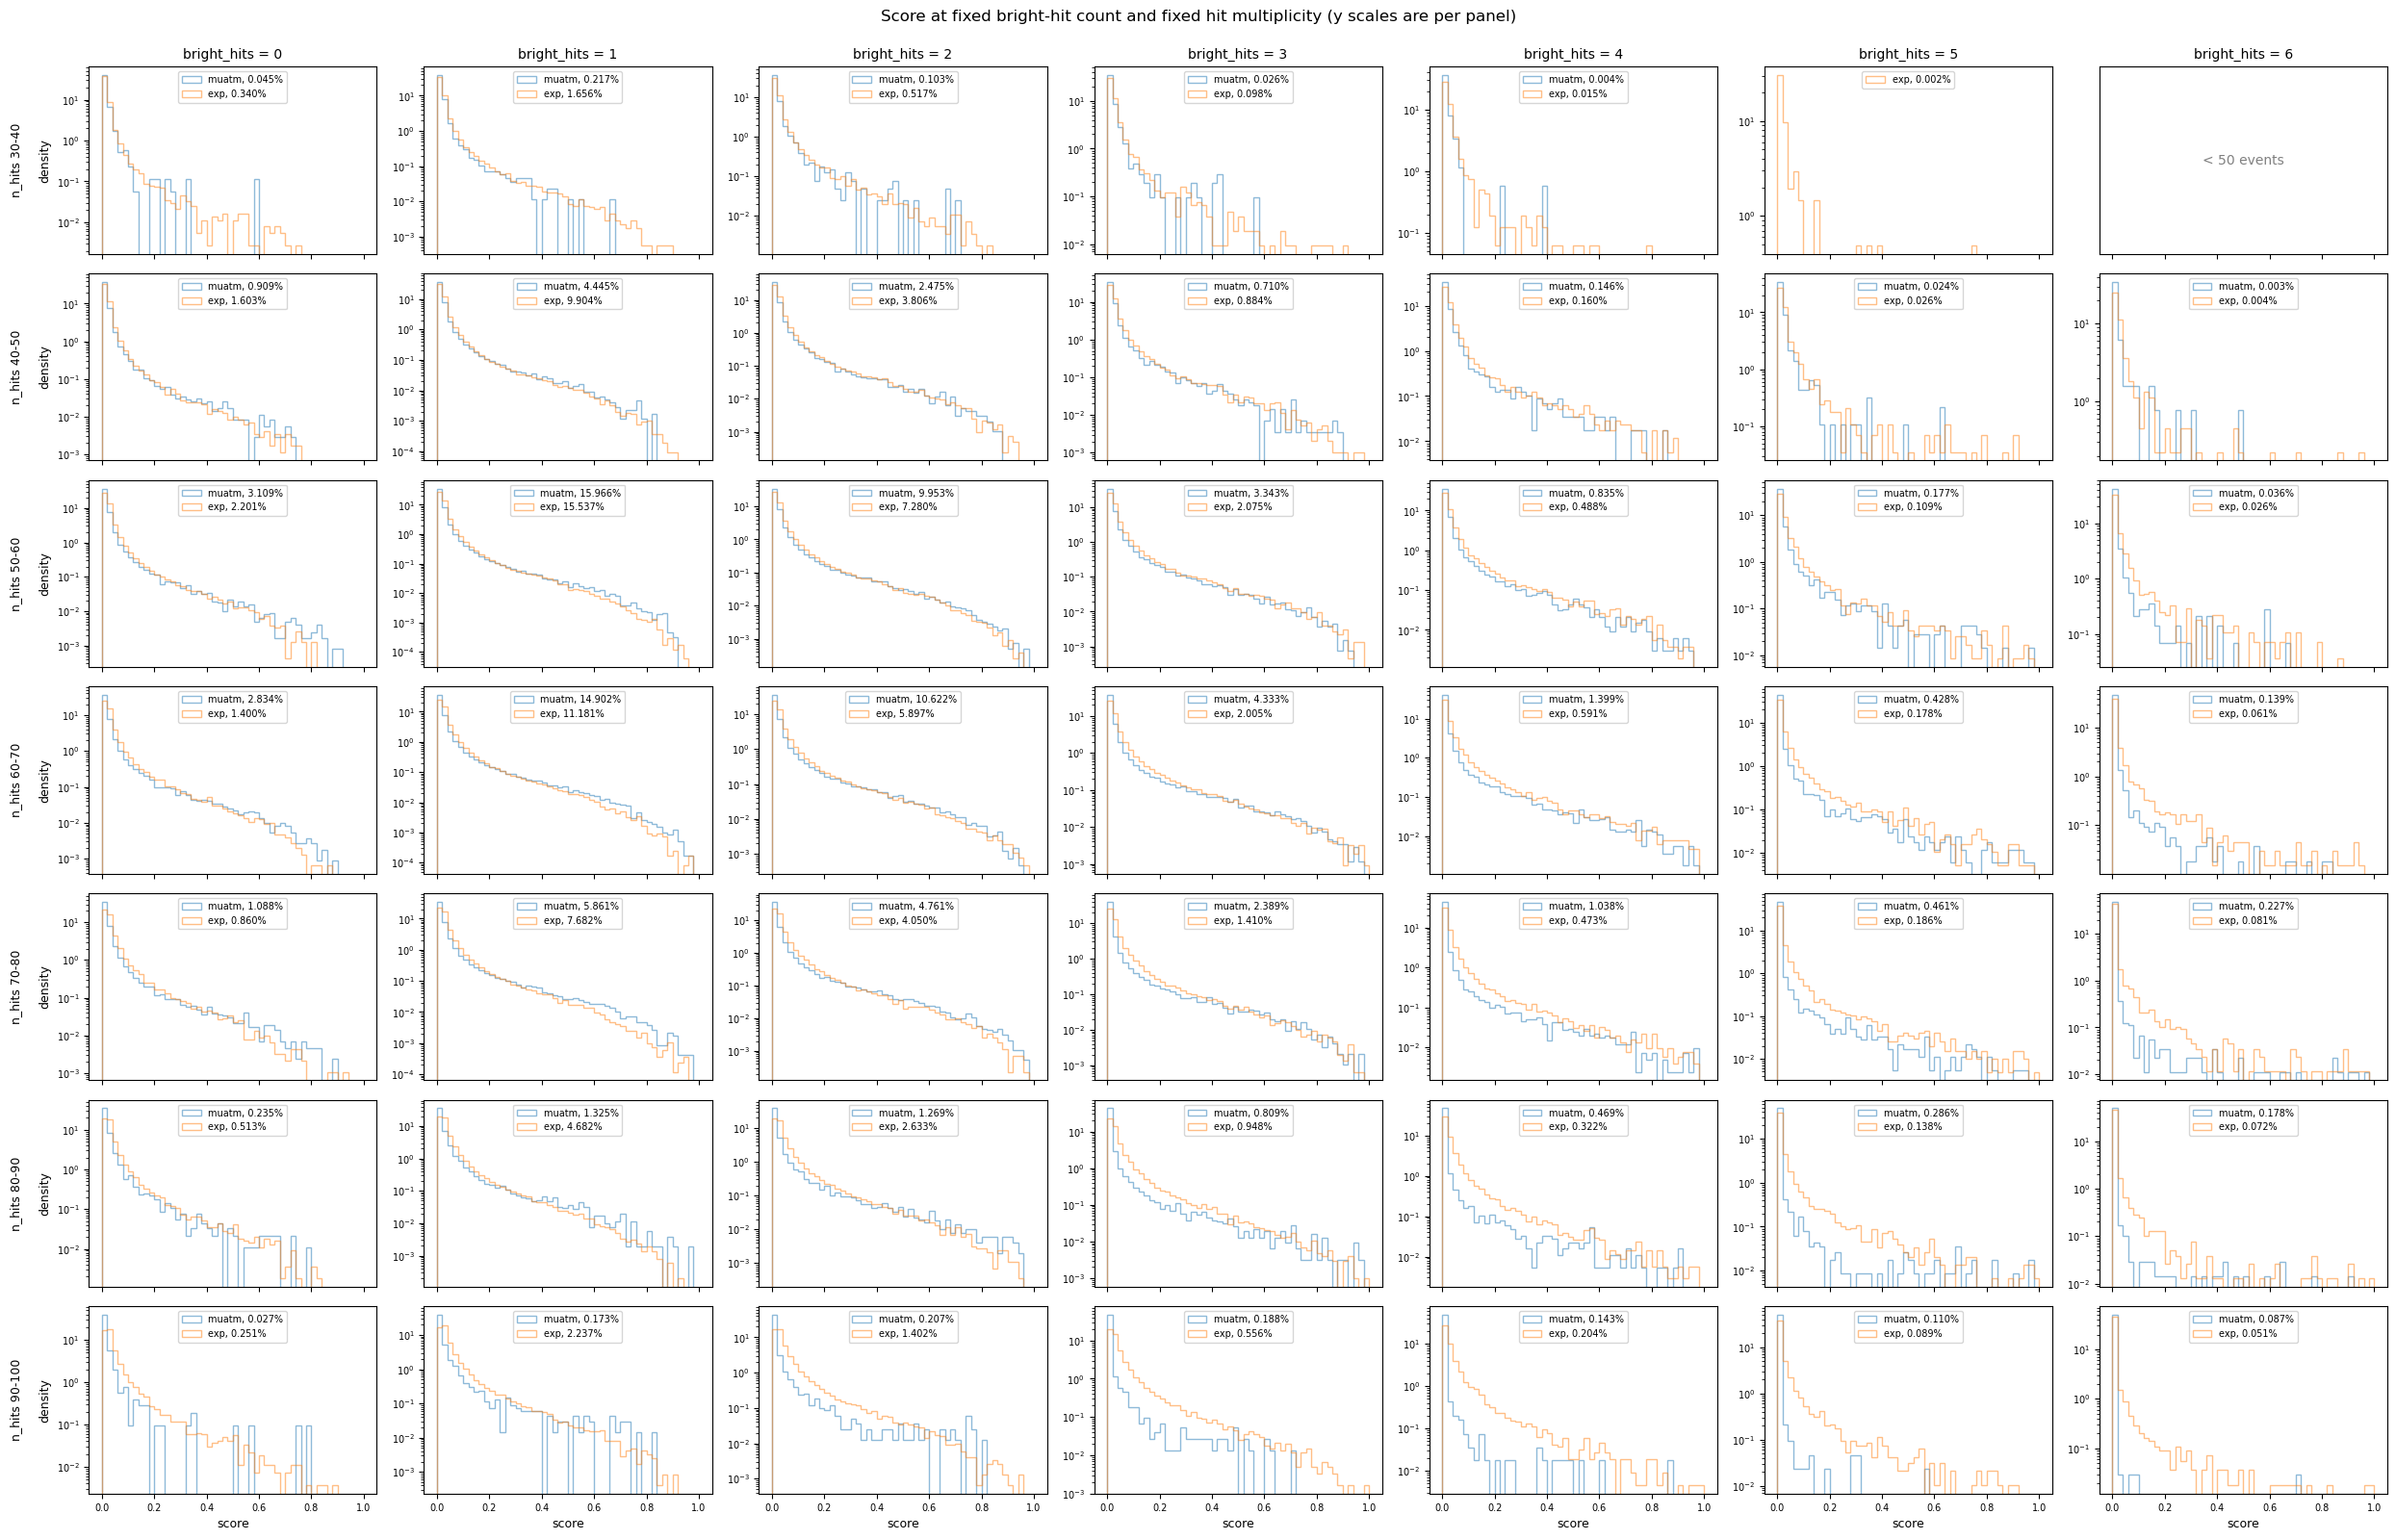

In [ ]:
bright_values = range(0, 7)              # bright_hits == m
hit_band_starts = list(range(30, 91, 10))      # n_hits in [n, n + 10)
MINIMUM_EVENTS = 50                      # below this a density is not worth drawing

colours = {"muatm": "tab:blue", "exp": "tab:orange"}

fig, axes = plt.subplots(len(hit_band_starts), len(bright_values),
                         figsize=(25, 16), sharex=True)

for row, n in enumerate(hit_band_starts):
    for col, m in enumerate(bright_values):
        ax = axes[row, col]
        drawn = False
        for name, df in (("muatm", muatm), ("exp", exp)):
            selected = df[(df.bright_hits == m)
                          & (df.n_hits >= n) & (df.n_hits < n + 10)]
            if len(selected) < MINIMUM_EVENTS:
                continue
            ax.hist(selected.score, label=f"{name}, {len(selected)/len(df):.3%}", log=True,
                    color=colours[name], range=(0,1), **hist_kwargs)
            drawn = True
        if not drawn:
            ax.text(0.5, 0.5, f"< {MINIMUM_EVENTS} events", ha="center", va="center",
                    transform=ax.transAxes, color="0.5")
            ax.set_yticks([])
        else:
            ax.legend(fontsize=7, loc="upper center")
        if row == 0:
            ax.set_title(f"bright_hits = {m}", fontsize=10)
        if col == 0:
            ax.set_ylabel(f"n_hits {n}-{n + 10}\n\ndensity", fontsize=9)
        if row == len(hit_band_starts) - 1:
            ax.set_xlabel("score", fontsize=9)
        ax.tick_params(labelsize=7)

fig.suptitle("Score at fixed bright-hit count and fixed hit multiplicity "
             "(y scales are per panel)", y=0.997)
fig.tight_layout()
plt.savefig("figures/score_by_bright_and_n_hits.png", dpi=300, bbox_inches="tight")
plt.show()


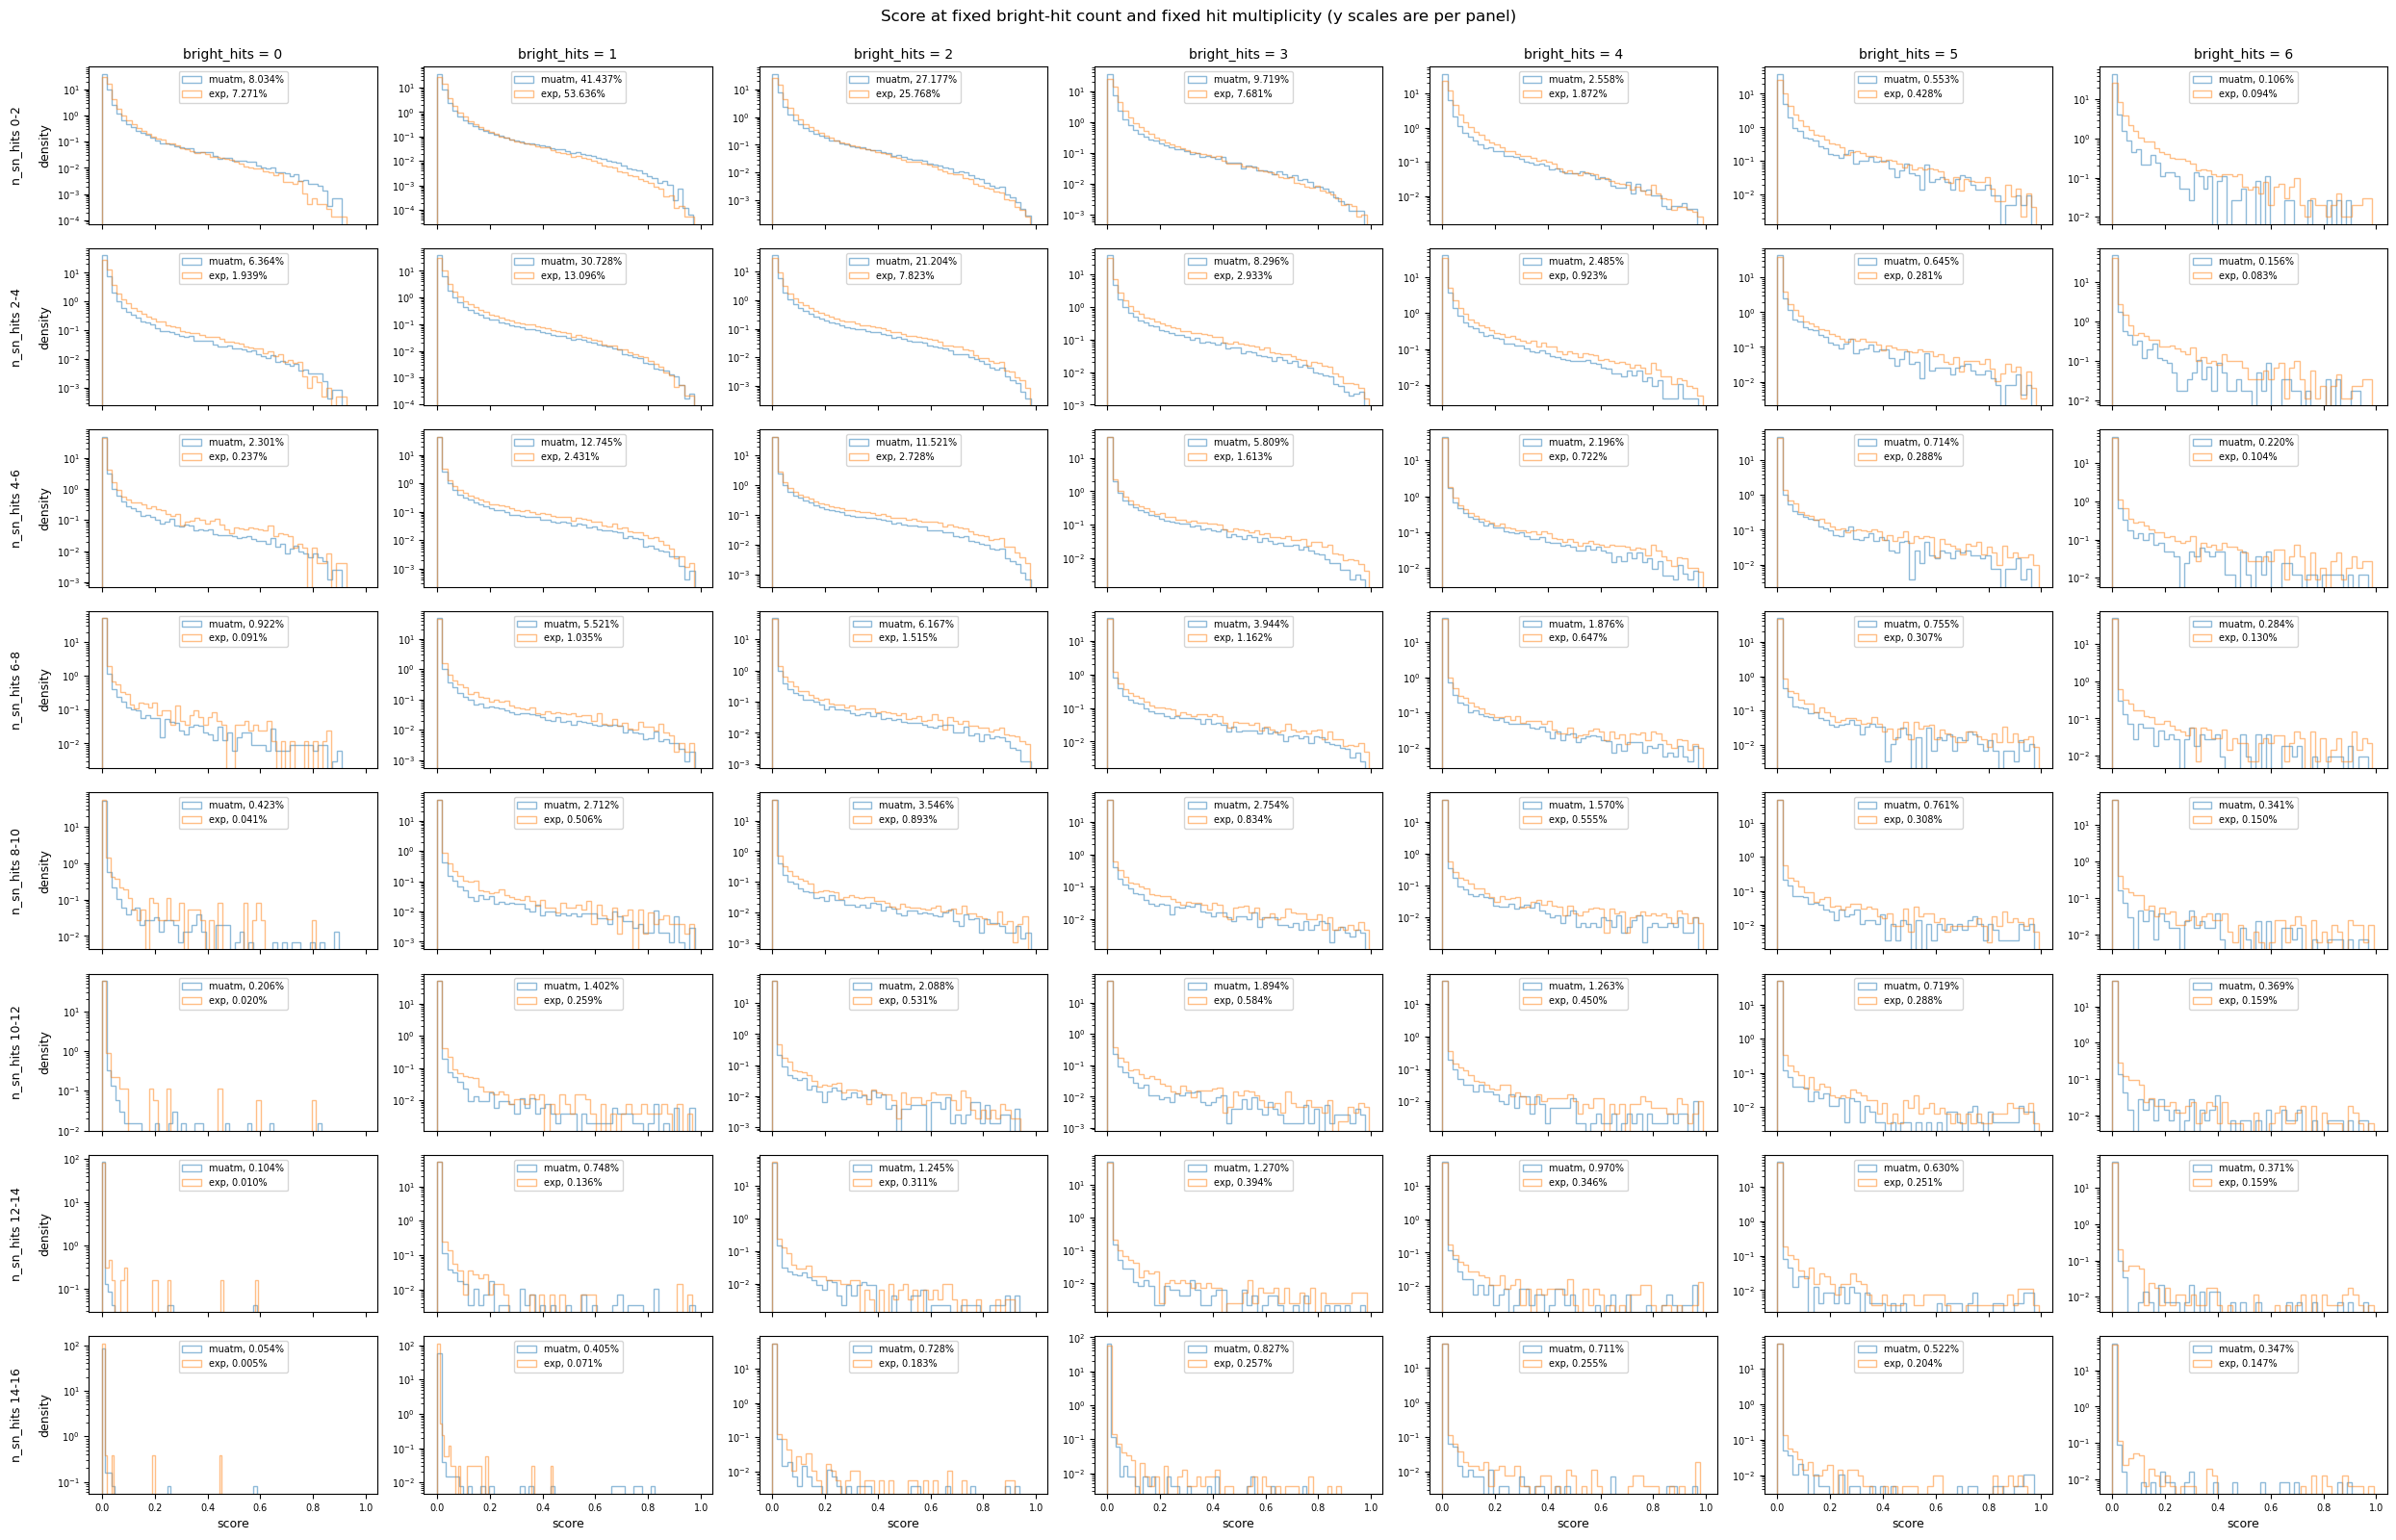

In [ ]:
bright_values = range(0, 7)              # bright_hits == m
sig_hit_band_starts = list(range(8, 16, 2))      # n_sn_hits in [n, n + 10)
MINIMUM_EVENTS = 50                      # below this a density is not worth drawing

colours = {"muatm": "tab:blue", "exp": "tab:orange"}

fig, axes = plt.subplots(len(sig_hit_band_starts), len(bright_values),
                         figsize=(25, 16), sharex=True)

for row, n in enumerate(sig_hit_band_starts):
    for col, m in enumerate(bright_values):
        ax = axes[row, col]
        drawn = False
        for name, df in (("muatm", muatm), ("exp", exp)):
            selected = df[(df.bright_hits == m)
                          & (df.n_sn_hits >= n) & (df.n_sn_hits < n + 10)]
            if len(selected) < MINIMUM_EVENTS:
                continue
            ax.hist(selected.score, label=f"{name}, {len(selected)/len(df):.3%}", log=True,
                    color=colours[name], **hist_kwargs)
            drawn = True
        if not drawn:
            ax.text(0.5, 0.5, f"< {MINIMUM_EVENTS} events", ha="center", va="center",
                    transform=ax.transAxes, color="0.5")
            ax.set_yticks([])
        else:
            ax.legend(fontsize=7, loc="upper center")
        if row == 0:
            ax.set_title(f"bright_hits = {m}", fontsize=10)
        if col == 0:
            ax.set_ylabel(f"n_sn_hits {n}-{n + 2}\n\ndensity", fontsize=9)
        if row == len(sig_hit_band_starts) - 1:
            ax.set_xlabel("score", fontsize=9)
        ax.tick_params(labelsize=7)

fig.suptitle("Score at fixed bright-hit count and fixed hit multiplicity "
             "(y scales are per panel)", y=0.997)
fig.tight_layout()
plt.savefig("figures/score_by_bright_and_n_signal_hits.png", dpi=300, bbox_inches="tight")
plt.show()


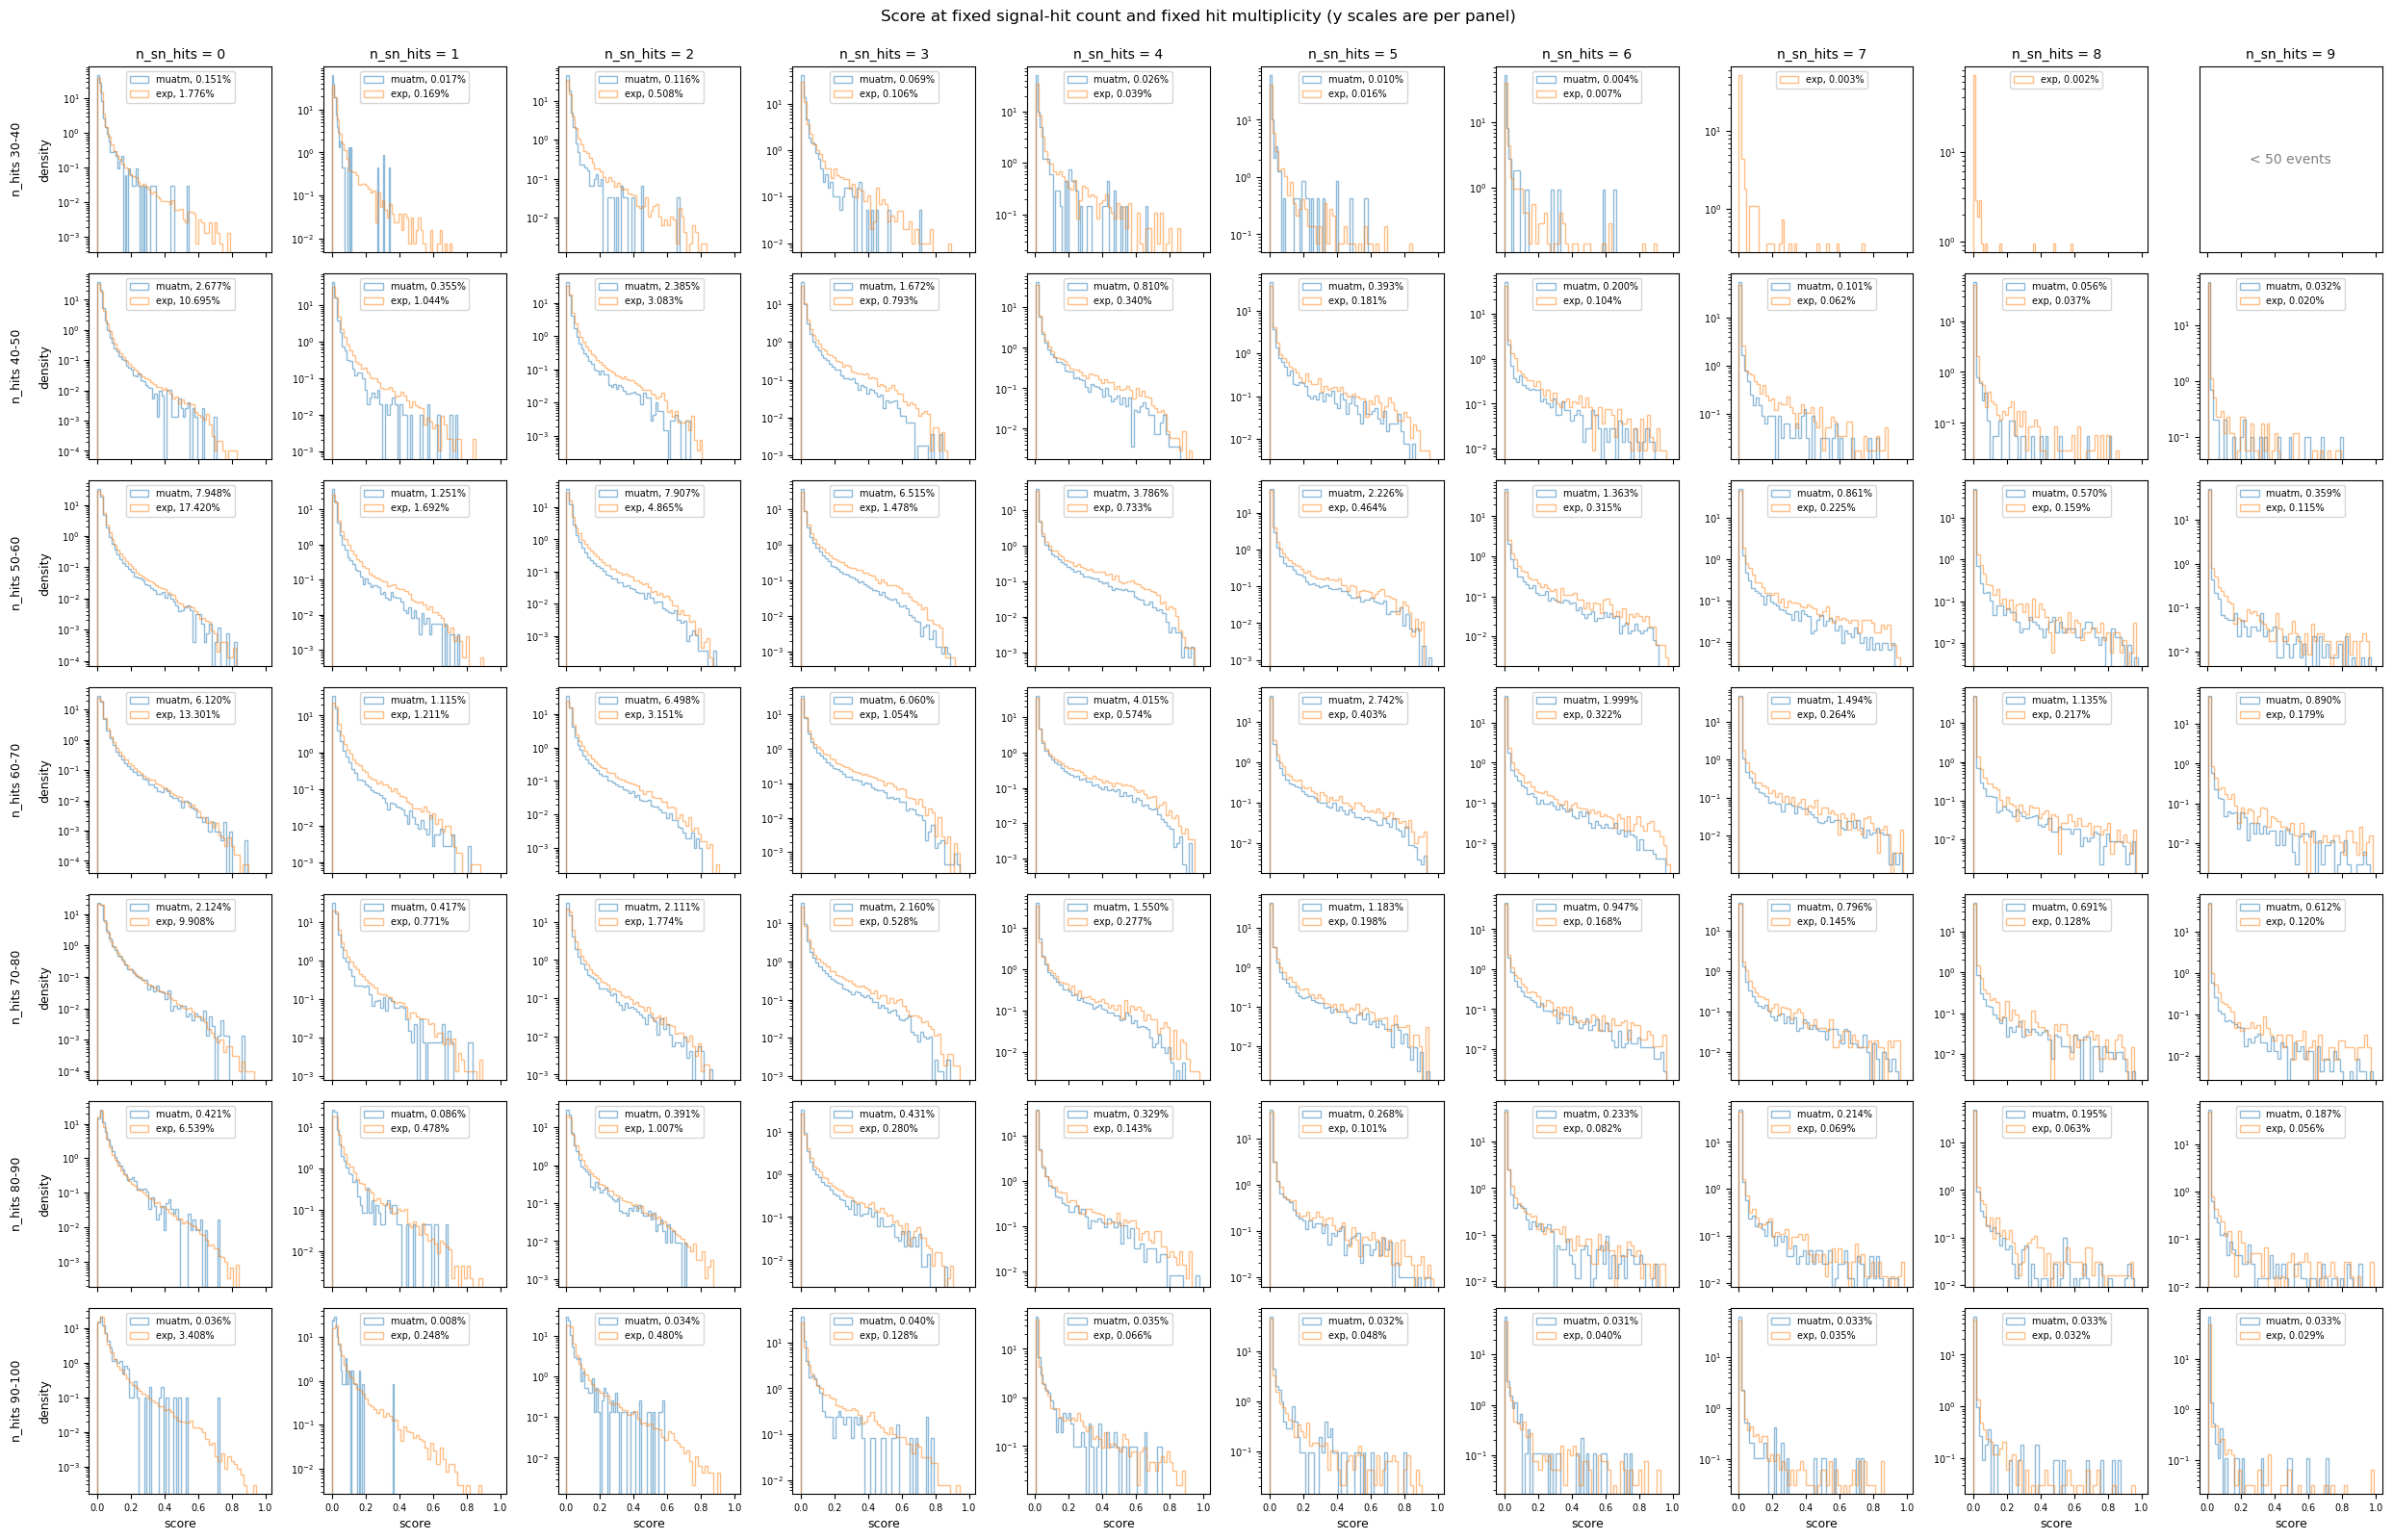

In [ ]:
sn_hits_starts = range(0, 10)              # n_sn_hits == m
hit_band_starts = list(range(30, 91, 10))      # n_hits in [n, n + 10)
MINIMUM_EVENTS = 50                      # below this a density is not worth drawing

colours = {"muatm": "tab:blue", "exp": "tab:orange"}

fig, axes = plt.subplots(len(hit_band_starts), len(sn_hits_starts),
                         figsize=(25, 16), sharex=True)

for row, n in enumerate(hit_band_starts):
    for col, m in enumerate(sn_hits_starts):
        ax = axes[row, col]
        drawn = False
        for name, df in (("muatm", muatm), ("exp", exp)):
            selected = df[(df.n_sn_hits == m)
                          & (df.n_hits >= n) & (df.n_hits < n + 10)]
            if len(selected) < MINIMUM_EVENTS:
                continue
            ax.hist(selected.score, label=f"{name}, {len(selected)/len(df):.3%}", log=True,
                    color=colours[name], **hist_kwargs)
            drawn = True
        if not drawn:
            ax.text(0.5, 0.5, f"< {MINIMUM_EVENTS} events", ha="center", va="center",
                    transform=ax.transAxes, color="0.5")
            ax.set_yticks([])
        else:
            ax.legend(fontsize=7, loc="upper center")
        if row == 0:
            ax.set_title(f"n_sn_hits = {m}", fontsize=10)
        if col == 0:
            ax.set_ylabel(f"n_hits {n}-{n + 10}\n\ndensity", fontsize=9)
        if row == len(hit_band_starts) - 1:
            ax.set_xlabel("score", fontsize=9)
        ax.tick_params(labelsize=7)

fig.suptitle("Score at fixed signal-hit count and fixed hit multiplicity "
             "(y scales are per panel)", y=0.997)
fig.tight_layout()
plt.savefig("figures/score_by_signal_and_n_hits.png", dpi=300, bbox_inches="tight")
plt.show()


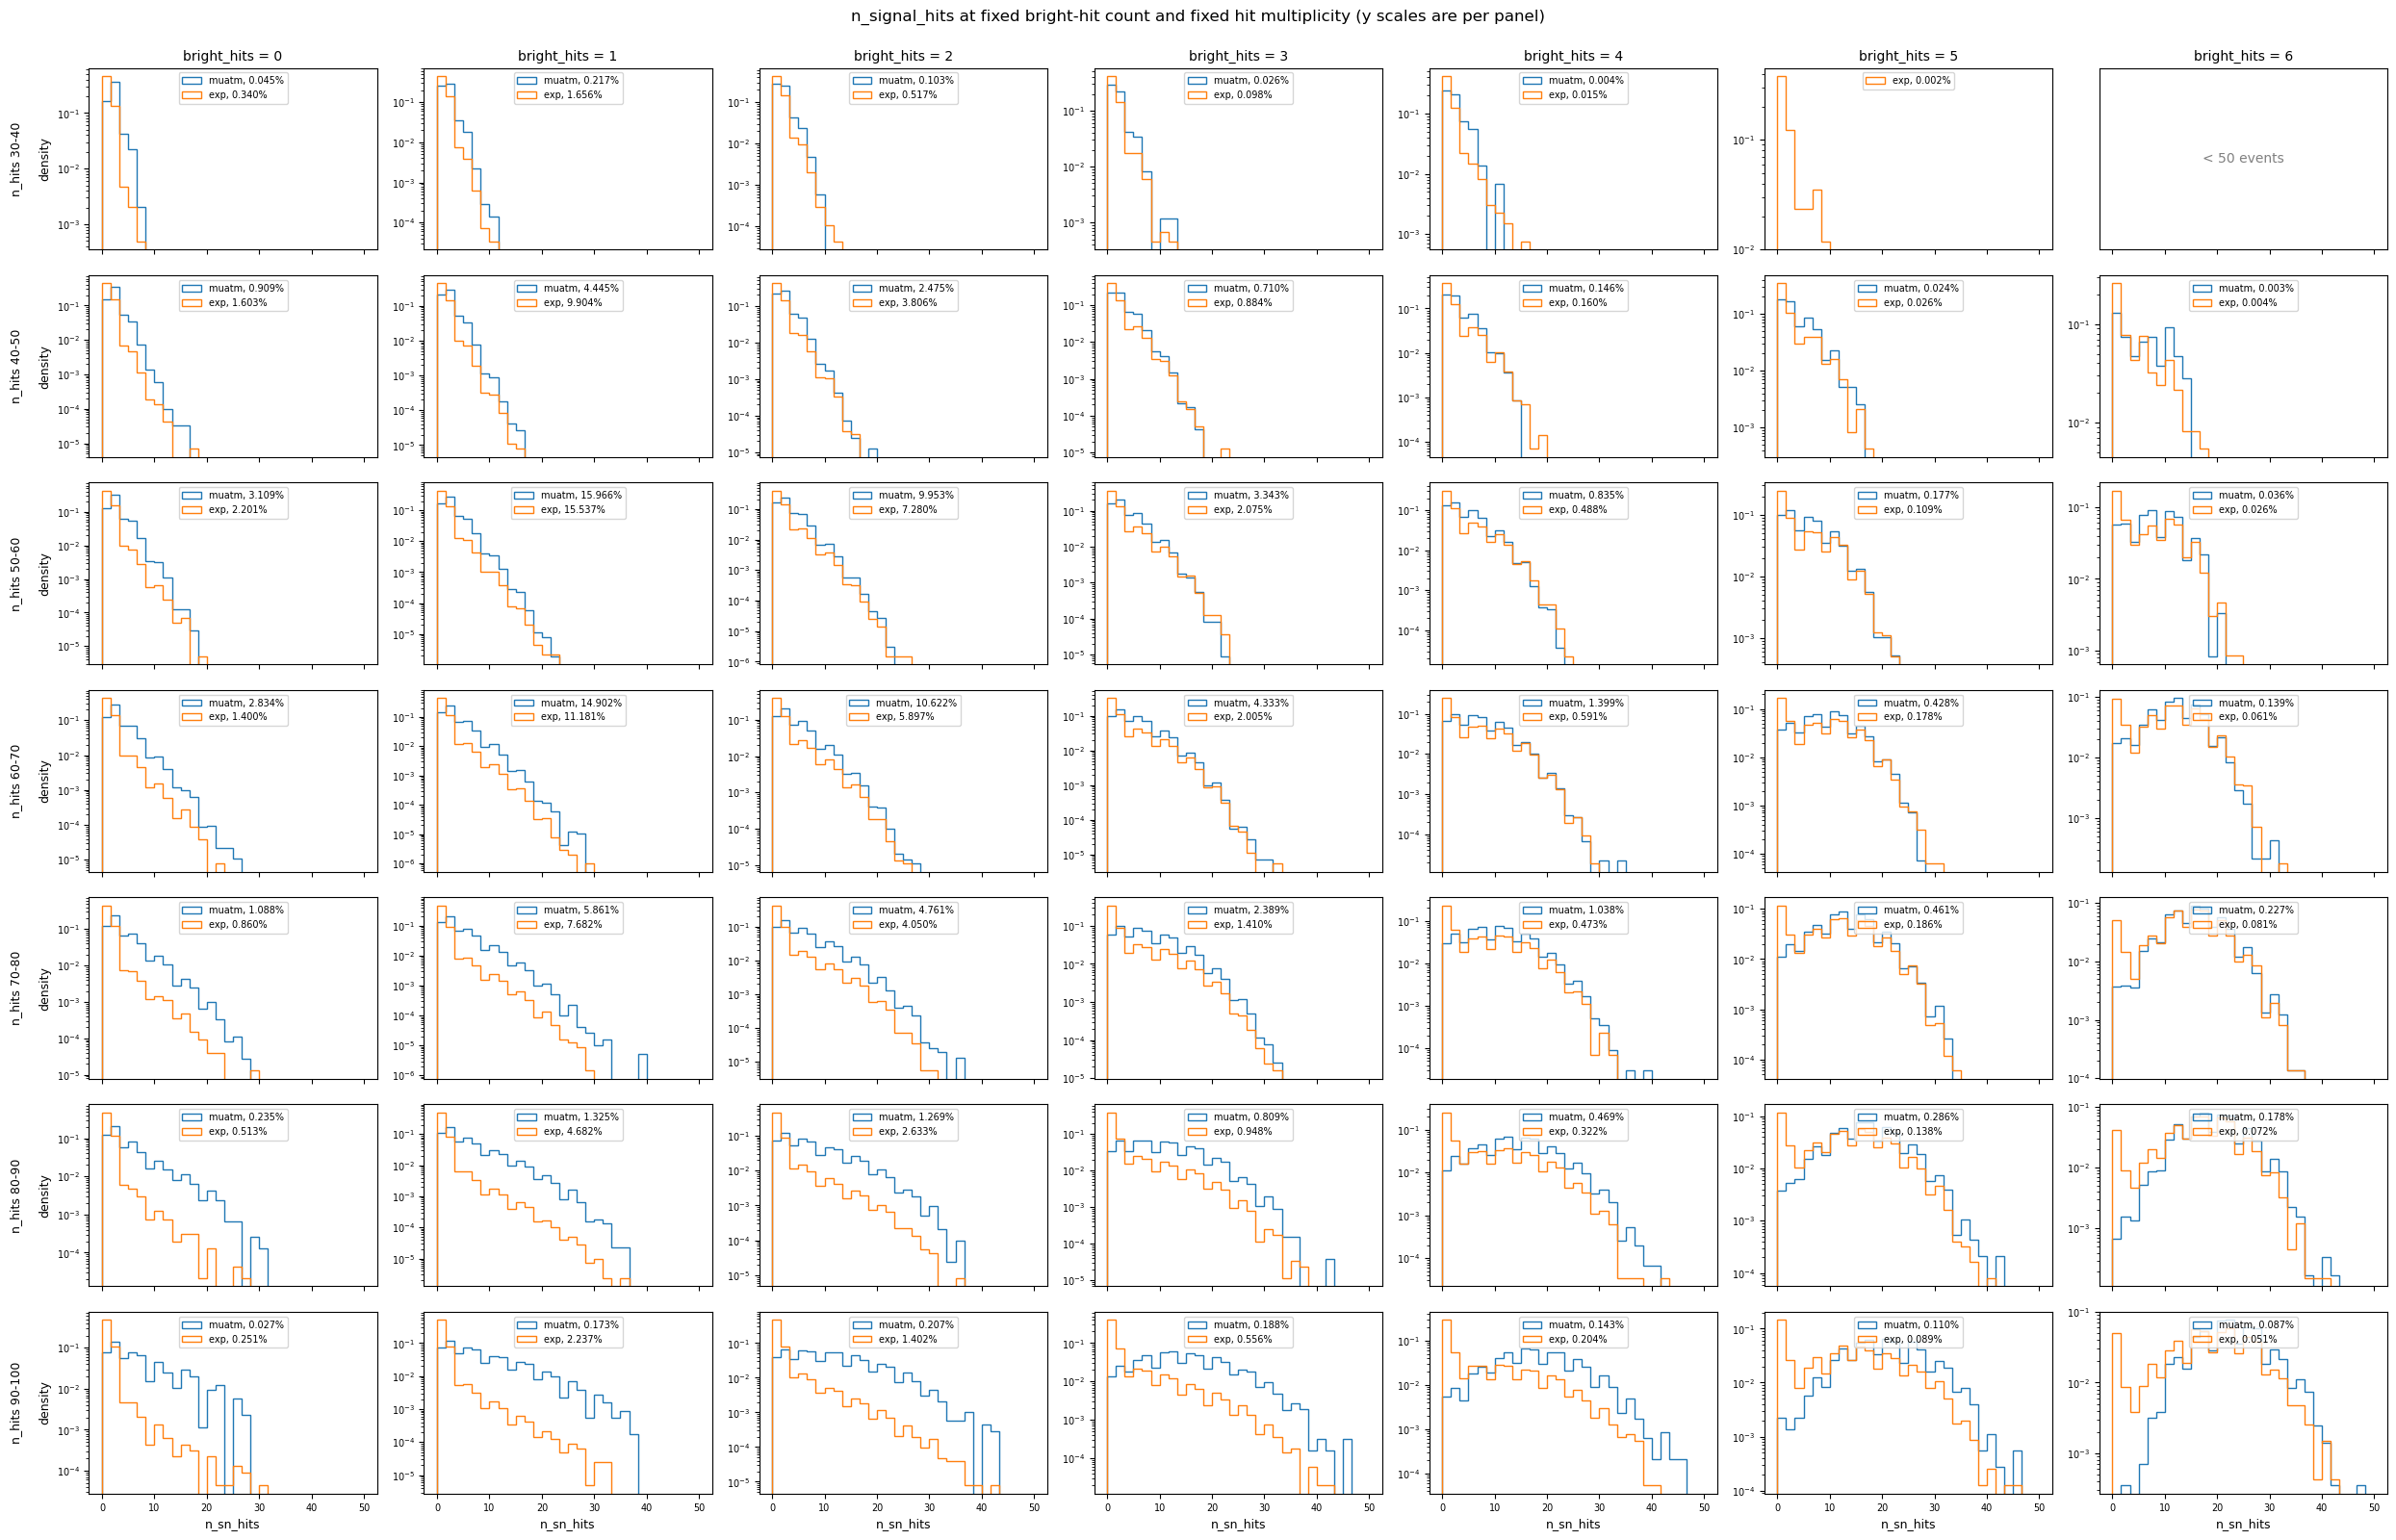

In [18]:
bright_values = range(0, 7)              # bright_hits == m
hit_band_starts = list(range(30, 91, 10))      # n_hits in [n, n + 10)
MINIMUM_EVENTS = 50                      # below this a density is not worth drawing

colours = {"muatm": "tab:blue", "exp": "tab:orange"}

fig, axes = plt.subplots(len(hit_band_starts), len(bright_values),
                         figsize=(25, 16), sharex=True)

for row, n in enumerate(hit_band_starts):
    for col, m in enumerate(bright_values):
        ax = axes[row, col]
        drawn = False
        for name, df in (("muatm", muatm), ("exp", exp)):
            selected = df[(df.bright_hits == m)
                          & (df.n_hits >= n) & (df.n_hits < n + 10)]
            if len(selected) < MINIMUM_EVENTS:
                continue
            ax.hist(selected.n_sn_hits, label=f"{name}, {len(selected)/len(df):.3%}", log=True,
                    color=colours[name], bins=30, histtype='step', range=(0,50), density=True)
            drawn = True
        if not drawn:
            ax.text(0.5, 0.5, f"< {MINIMUM_EVENTS} events", ha="center", va="center",
                    transform=ax.transAxes, color="0.5")
            ax.set_yticks([])
        else:
            ax.legend(fontsize=7, loc="upper center")
        if row == 0:
            ax.set_title(f"bright_hits = {m}", fontsize=10)
        if col == 0:
            ax.set_ylabel(f"n_hits {n}-{n + 10}\n\ndensity", fontsize=9)
        if row == len(hit_band_starts) - 1:
            ax.set_xlabel("n_sn_hits", fontsize=9)
        ax.tick_params(labelsize=7)

fig.suptitle("n_signal_hits at fixed bright-hit count and fixed hit multiplicity "
             "(y scales are per panel)", y=0.997)
fig.tight_layout()
plt.savefig("figures/n_signal_hits_by_bright_and_n_hits.png", dpi=300, bbox_inches="tight")
plt.show()


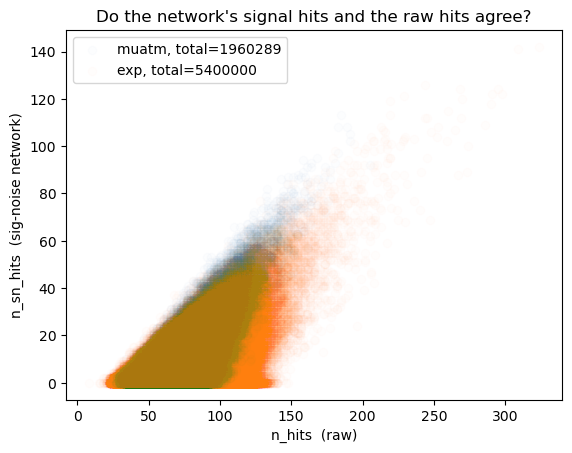

In [23]:
plt.scatter(muatm.n_hits, muatm.n_sn_hits, label=f"muatm, total={len(muatm)}", alpha=0.01)
plt.scatter(exp.n_hits, exp.n_sn_hits, label=f"exp, total={len(exp)}", alpha=0.01)
plt.xlabel("n_hits  (raw)")
plt.ylabel("n_sn_hits  (sig-noise network)")
plt.legend()
plt.title("Do the network's signal hits and the raw hits agree?")
plt.show()

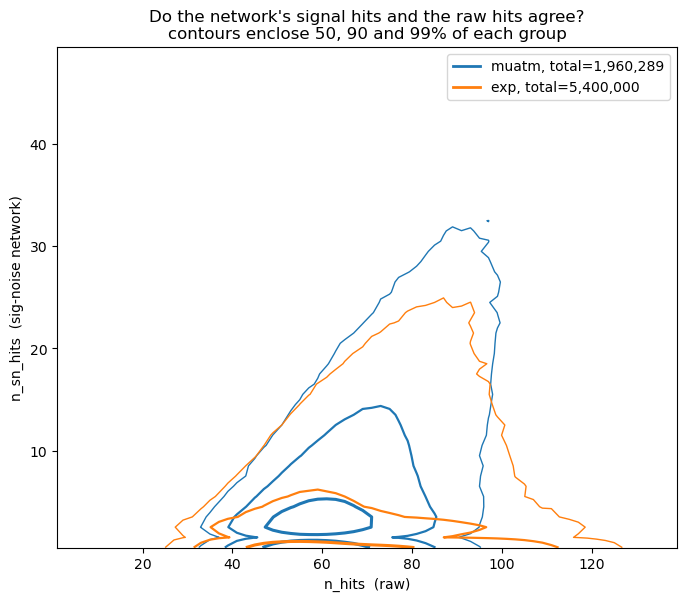

In [22]:
# Contours enclosing a given share of events, rather than arbitrary density values:
# "90% of muatm events live inside this line" is readable, "density = 3e-5" is not.
ENCLOSED = (0.5, 0.9, 0.99)
hit_edges = np.linspace(0, 140, 71)      # p99.9 is 115 (muatm) and 126 (exp)
signal_edges = np.linspace(0, 50, 51)    # p99.9 is 44 and 36

def density(df):
    counts, _, _ = np.histogram2d(df.n_hits, df.n_sn_hits,
                                  bins=[hit_edges, signal_edges])
    return counts / counts.sum()

def levels_enclosing(grid, shares=ENCLOSED):
    """Density levels below which the stated share of all events lies."""
    ordered = np.sort(grid.ravel())[::-1]
    enclosed = np.cumsum(ordered)
    return sorted({float(ordered[np.searchsorted(enclosed, share)]) for share in shares})

centres = lambda edges: 0.5 * (edges[:-1] + edges[1:])
grid_x, grid_y = np.meshgrid(centres(hit_edges), centres(signal_edges), indexing="ij")

fig, ax = plt.subplots(figsize=(8, 6.5))
for name, df, colour in (("muatm", muatm, "tab:blue"), ("exp", exp, "tab:orange")):
    grid = density(df)
    ax.contour(grid_x, grid_y, grid, levels=levels_enclosing(grid),
               colors=colour, linewidths=(1.0, 1.6, 2.2))
    ax.plot([], [], color=colour, lw=2, label=f"{name}, total={len(df):,}")

ax.set(xlabel="n_hits  (raw)", ylabel="n_sn_hits  (sig-noise network)",
       title="Do the network's signal hits and the raw hits agree?\n"
             "contours enclose 50, 90 and 99% of each group")
ax.legend()
plt.show()
